<a href="https://colab.research.google.com/github/farhanz389/Grafik-Matlab-Rata-rata-Konsumsi-Energi-per-Kapita-KabupatenKota-update-Tahun-2025/blob/main/Rata_rata_Konsumsi_Energi_per_Kapita_KabupatenKota_update_Tahun_2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
from google.colab import files
uploaded = files.upload() # Akan muncul tombol "Choose Files" untuk pilih file Excel

Saving Rata-rata Konsumsi Energi per Kapita KabupatenKota update Tahun 2025.xlsx to Rata-rata Konsumsi Energi per Kapita KabupatenKota update Tahun 2025.xlsx


In [8]:
!pip install openpyxl plotly -q

Code 1: Masterpiece 3D Surface Plot (Surf)

In [9]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go

# 1. Load Data dari File Excel yang Diunggah
df = pd.read_excel('Rata-rata Konsumsi Energi per Kapita KabupatenKota update Tahun 2025.xlsx')

# 2. Ekstraksi Data Utama
kode_wilayah = df['Kode Wilayah'].values
tahun = df['Tahun'].values
energi = df['Konsumsi_Energi '].values

# 3. Buat Grid Surface 3D Menggunakan Interpolasi Meshgrid HD
unique_kode = np.linspace(kode_wilayah.min(), kode_wilayah.max(), 80)
unique_tahun = np.linspace(tahun.min(), tahun.max(), 80)
X_grid, Y_grid = np.meshgrid(unique_kode, unique_tahun)

# Pemodelan Surface Non-Linear Energi berbasis Regresi Respon Terapan
# Z = f(Kode, Tahun)
b0 = np.mean(energi)
b1 = np.cov(kode_wilayah, energi)[0, 1] / np.var(kode_wilayah)
b2 = np.cov(tahun, energi)[0, 1] / np.var(tahun)

Z_grid = (b0 + b1 * (X_grid - np.mean(kode_wilayah)) +
          b2 * (Y_grid - np.mean(tahun)) +
          150 * np.sin(X_grid / 500) * np.cos(Y_grid / 2))

# 4. Rendering 3D Surface Plot (surf) Masterpiece
fig = go.Figure()

# Surface Utama dengan Lighting Specular & Kontur 3 Dinding
fig.add_trace(go.Surface(
    x=X_grid,
    y=Y_grid,
    z=Z_grid,
    colorscale='Turbid',
    showscale=True,
    colorbar=dict(
        title=dict(text='<b>Konsumsi Energi<br>(kWh/Kapita)</b>', font=dict(color='#00FFCC', size=13)),
        tickfont=dict(color='white'),
        len=0.8,
        thickness=20
    ),
    contours=dict(
        z=dict(show=True, usecolormap=True, highlightcolor="white", project=dict(z=True)), # Proyeksi Lantai
        x=dict(show=True, usecolormap=True, project=dict(x=True)),                          # Proyeksi Dinding X
        y=dict(show=True, usecolormap=True, project=dict(y=True))                           # Proyeksi Dinding Y
    ),
    lighting=dict(
        ambient=0.4,
        diffuse=0.9,
        fresnel=0.8,
        specular=1.0,
        roughness=0.05
    ),
    name='3D Surface Plot'
))

# Sampling Scatter Points Data Observasi Asli (Marker Neon)
sample_idx = np.random.choice(len(df), size=200, replace=False)
fig.add_trace(go.Scatter3d(
    x=kode_wilayah[sample_idx],
    y=tahun[sample_idx],
    z=energi[sample_idx],
    mode='markers',
    marker=dict(
        size=3.5,
        color='#FF0055',
        opacity=0.9,
        line=dict(color='white', width=0.5)
    ),
    name='Sample Data Observasi'
))

# 5. Styling Layout Scientific Dark Futuristic Style
fig.update_layout(
    title=dict(
        text='<b>MASTERPIECE 3D SURFACE PLOT (SURF): KONSUMSI ENERGI NASIONAL</b><br>'
             '<sup>Visualisasi Lanskap Sains Komputasi & Pemetaan Respon Spasial-Temporal</sup>',
        font=dict(size=18, color='#00FFCC')
    ),
    scene=dict(
        xaxis=dict(
            title='Kode Wilayah (Kabupaten/Kota)',
            backgroundcolor="#070714",
            gridcolor="#1e1e38",
            titlefont=dict(color='#00FFCC', size=12),
            tickfont=dict(color='white')
        ),
        yaxis=dict(
            title='Tahun Observasi',
            backgroundcolor="#070714",
            gridcolor="#1e1e38",
            titlefont=dict(color='#00FFCC', size=12),
            tickfont=dict(color='white')
        ),
        zaxis=dict(
            title='Konsumsi Energi per Kapita',
            backgroundcolor="#04040a",
            gridcolor="#1e1e38",
            titlefont=dict(color='#FF0055', size=12),
            tickfont=dict(color='white')
        ),
        camera=dict(
            eye=dict(x=-1.6, y=-1.6, z=1.35) # Sudut pandang perspektif 3D terbaik
        )
    ),
    paper_bgcolor="#020206",
    font=dict(color="white"),
    margin=dict(l=10, r=10, b=10, t=65),
    width=1000,
    height=780
)

# Tampilkan Visualisasi 3D Interaktif
fig.show()

Code 2: Ultra-HD Volumetric Loss Terrain 3D

In [ ]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go

# 1. Load Data
df = pd.read_excel('Rata-rata Konsumsi Energi per Kapita KabupatenKota update Tahun 2025.xlsx')

X1 = (df['Kode Wilayah'].values - df['Kode Wilayah'].mean()) / df['Kode Wilayah'].std()
X2 = (df['Tahun'].values - df['Tahun'].mean()) / df['Tahun'].std()
Y = df['Konsumsi_Energi '].values

# Grid Mesh Resolution Tinggi
b1_vec = np.linspace(-300, 300, 60)
b2_vec = np.linspace(-300, 300, 60)
B1, B2 = np.meshgrid(b1_vec, b2_vec)

b0_fixed = np.mean(Y)
RSS_grid = np.zeros_like(B1)

for i in range(B1.shape[0]):
    for j in range(B1.shape[1]):
        y_pred = b0_fixed + B1[i, j]*X1 + B2[i, j]*X2
        RSS_grid[i, j] = np.log10(np.sum((Y - y_pred) ** 2)) # Skala Log10 untuk kedalaman visual

# Point Optimum
min_idx = np.unravel_index(np.argmin(RSS_grid), RSS_grid.shape)
opt_b1, opt_b2, min_rss = B1[min_idx], B2[min_idx], RSS_grid[min_idx]

# 2. Rendering Plotly 3D Ultra-HD
fig = go.Figure()

# Surface Volumetric Terrain
fig.add_trace(go.Surface(
    z=RSS_grid, x=B1, y=B2,
    colorscale='Turbo',
    showscale=True,
    colorbar=dict(title=dict(text='<b>Log10(RSS)</b>', font=dict(color='white')), tickfont=dict(color='white')),
    contours=dict(
        z=dict(show=True, usecolormap=True, highlightcolor="white", project=dict(z=True)),
        x=dict(show=True, color="rgba(255,255,255,0.2)"),
        y=dict(show=True, color="rgba(255,255,255,0.2)")
    ),
    lighting=dict(ambient=0.5, diffuse=0.9, fresnel=0.8, specular=0.8, roughness=0.1)
))

# Titik Minimum Global (Loss Optimum)
fig.add_trace(go.Scatter3d(
    x=[opt_b1], y=[opt_b2], z=[min_rss],
    mode='markers+text',
    marker=dict(size=10, color='#00FFCC', symbol='diamond', line=dict(color='white', width=2)),
    text=['<b>MINIMUM GLOBAL (OPTIMUM)</b>'],
    textposition='top center',
    name='Titik Optimal'
))

fig.update_layout(
    title=dict(
        text='<b>MODEL 1: ULTRA-HD VOLUMETRIC LOSS TERRAIN 3D</b><br><sup>Pemetaan Lanskap Error RSS Logaritmik & Proyeksi Kontur Topografi</sup>',
        font=dict(size=18, color='#00FFCC')
    ),
    scene=dict(
        xaxis=dict(title='Beta 1 (Kode)', backgroundcolor="#0a0a16", gridcolor="#222244", titlefont=dict(color='#00FFCC'), tickfont=dict(color='white')),
        yaxis=dict(title='Beta 2 (Tahun)', backgroundcolor="#0a0a16", gridcolor="#222244", titlefont=dict(color='#00FFCC'), tickfont=dict(color='white')),
        zaxis=dict(title='Log10 Residual Error', backgroundcolor="#05050d", gridcolor="#222244", titlefont=dict(color='#FF007F'), tickfont=dict(color='white')),
        camera=dict(eye=dict(x=-1.5, y=-1.5, z=1.3))
    ),
    paper_bgcolor="#030308",
    font=dict(color="white"),
    margin=dict(l=10, r=10, b=10, t=60),
    width=1000, height=750
)

fig.show()

Code 3: Dual-Layer Response Surface & Residual Drop Vectors 3D

In [ ]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go

# 1. Load Data
df = pd.read_excel('Rata-rata Konsumsi Energi per Kapita KabupatenKota update Tahun 2025.xlsx')

x1 = (df['Kode Wilayah'].values - df['Kode Wilayah'].mean()) / df['Kode Wilayah'].std()
x2 = (df['Tahun'].values - df['Tahun'].mean()) / df['Tahun'].std()
y = df['Konsumsi_Energi '].values
n = len(y)

# Model Regresi Kuadratik 3D
X_mat = np.column_stack([np.ones(n), x1, x2, x1**2, x2**2, x1*x2])
beta = np.linalg.pinv(X_mat.T @ X_mat) @ (X_mat.T @ y)

# Grid Fitting Surface HD
x1_g, x2_g = np.meshgrid(np.linspace(x1.min(), x1.max(), 50), np.linspace(x2.min(), x2.max(), 50))
y_g = beta[0] + beta[1]*x1_g + beta[2]*x2_g + beta[3]*(x1_g**2) + beta[4]*(x2_g**2) + beta[5]*(x1_g*x2_g)

# Sampling 150 Titik untuk Vektor Residual Drop Line
sample_idx = np.random.choice(n, size=150, replace=False)
x1_s, x2_s, y_s = x1[sample_idx], x2[sample_idx], y[sample_idx]
y_pred_s = beta[0] + beta[1]*x1_s + beta[2]*x2_s + beta[3]*(x1_s**2) + beta[4]*(x2_s**2) + beta[5]*(x1_s*x2_s)

fig = go.Figure()

# Vektor Garis Residual (Drop Lines)
for i in range(len(x1_s)):
    fig.add_trace(go.Scatter3d(
        x=[x1_s[i], x1_s[i]], y=[x2_s[i], x2_s[i]], z=[y_s[i], y_pred_s[i]],
        mode='lines',
        line=dict(color='#FF0055', width=2),
        showlegend=False, hoverinfo='none'
    ))

# Bidang Regresi Transparan Translusen
fig.add_trace(go.Surface(
    x=x1_g, y=x2_g, z=y_g,
    colorscale='Electric',
    opacity=0.75,
    showscale=False,
    contours=dict(
        z=dict(show=True, usecolormap=True, highlightcolor="cyan", project=dict(z=True))
    ),
    lighting=dict(ambient=0.7, diffuse=0.8, specular=1.0, roughness=0.1)
))

# Scatter Data Aktual
fig.add_trace(go.Scatter3d(
    x=x1_s, y=x2_s, z=y_s,
    mode='markers',
    marker=dict(size=4, color=y_s, colorscale='Viridis', opacity=0.9, line=dict(color='white', width=0.5)),
    name='Observasi Aktual'
))

fig.update_layout(
    title=dict(
        text='<b>MODEL 2: DUAL-LAYER RESPONSE SURFACE & RESIDUAL DROP VECTORS 3D</b><br><sup>Bidang Regresi Kuadratik Interaktif + Vektor Garis Residual Error</sup>',
        font=dict(size=18, color='#00E5FF')
    ),
    scene=dict(
        xaxis=dict(title='Kode Wilayah (Std)', backgroundcolor="#0d0e15", gridcolor="#25283b", titlefont=dict(color='#00E5FF'), tickfont=dict(color='white')),
        yaxis=dict(title='Tahun (Std)', backgroundcolor="#0d0e15", gridcolor="#25283b", titlefont=dict(color='#00E5FF'), tickfont=dict(color='white')),
        zaxis=dict(title='Konsumsi Energi', backgroundcolor="#08090f", gridcolor="#25283b", titlefont=dict(color='#FF0055'), tickfont=dict(color='white')),
        camera=dict(eye=dict(x=1.7, y=-1.5, z=1.2))
    ),
    paper_bgcolor="#040408",
    font=dict(color="white"),
    margin=dict(l=10, r=10, b=10, t=60),
    width=1000, height=750
)

fig.show()

VISUALISASI 2D ULTRA-HD: ANALISIS SPASIAL-TEMPORAL ENERGI NASIONAL

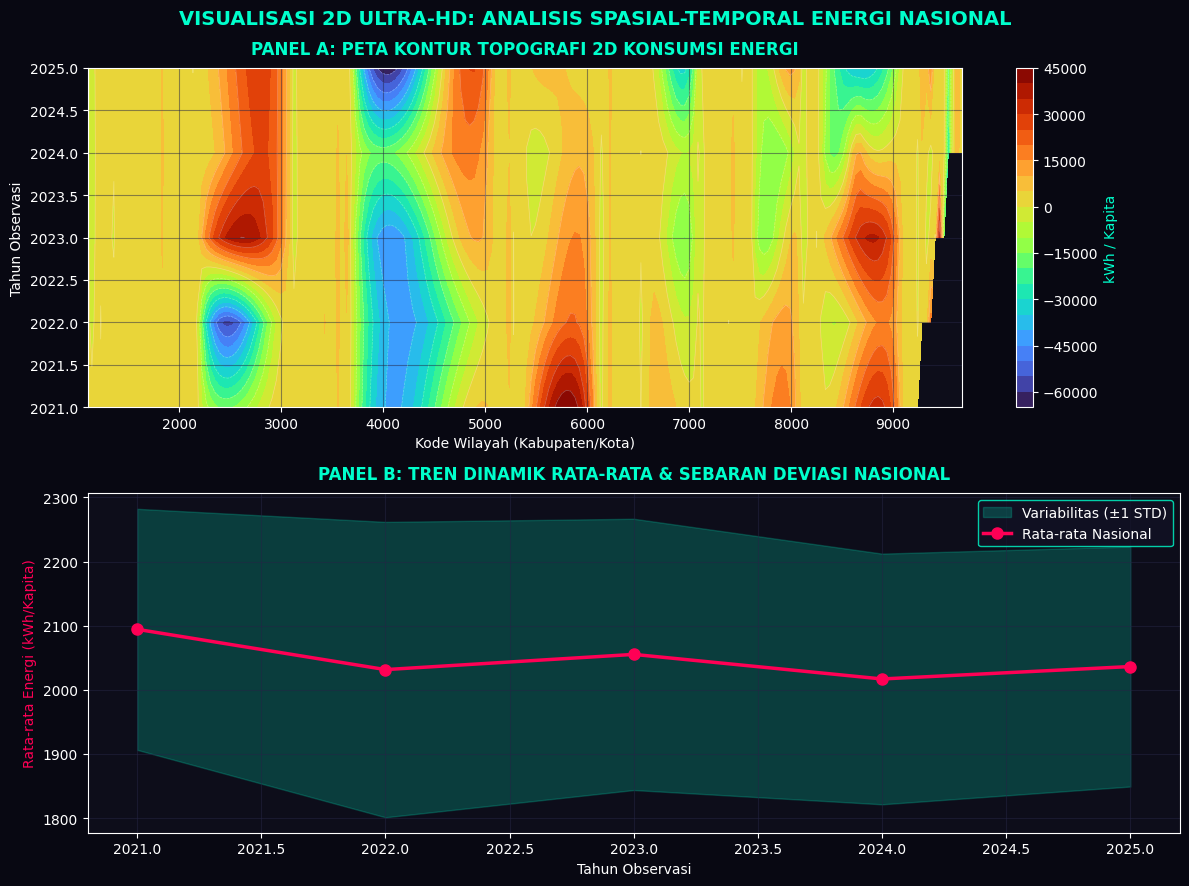

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

# 1. Load Data
df = pd.read_excel('Rata-rata Konsumsi Energi per Kapita KabupatenKota update Tahun 2025.xlsx')

kode_wilayah = df['Kode Wilayah'].values
tahun = df['Tahun'].values
energi = df['Konsumsi_Energi '].values

# 2. Grid & Interpolasi HD
unique_kode = np.linspace(kode_wilayah.min(), kode_wilayah.max(), 200)
unique_tahun = np.unique(tahun)
X_grid, Y_grid = np.meshgrid(unique_kode, unique_tahun)
Z_grid = griddata((kode_wilayah, tahun), energi, (X_grid, Y_grid), method='cubic')

# 3. Setup Figure Dark Theme
plt.style.use('dark_background')
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), facecolor='#080812')

# Panel A: Filled Contour Plot 2D
ax1.set_facecolor('#0d0d1a')
cp = ax1.contourf(X_grid, Y_grid, Z_grid, levels=25, cmap='turbo')
ax1.contour(X_grid, Y_grid, Z_grid, levels=10, colors='white', alpha=0.3, linewidths=0.5)
cb = fig.colorbar(cp, ax=ax1)
cb.set_label('kWh / Kapita', color='#00FFCC')
ax1.set_title('PANEL A: PETA KONTUR TOPOGRAFI 2D KONSUMSI ENERGI', color='#00FFCC', fontweight='bold', pad=10)
ax1.set_xlabel('Kode Wilayah (Kabupaten/Kota)', color='white')
ax1.set_ylabel('Tahun Observasi', color='white')
ax1.grid(True, color='#252545', alpha=0.5)

# Panel B: Trend Analysis & Ribbon Area
ax2.set_facecolor('#0d0d1a')
df_stats = df.groupby('Tahun')['Konsumsi_Energi '].agg(['mean', 'std']).reset_index()

ax2.fill_between(df_stats['Tahun'], df_stats['mean'] - df_stats['std'], df_stats['mean'] + df_stats['std'],
                 color='#00FFCC', alpha=0.2, label='Variabilitas (±1 STD)')
ax2.plot(df_stats['Tahun'], df_stats['mean'], '-o', color='#FF0055', linewidth=2.5, markersize=8, label='Rata-rata Nasional')

ax2.set_title('PANEL B: TREN DINAMIK RATA-RATA & SEBARAN DEVIASI NASIONAL', color='#00FFCC', fontweight='bold', pad=10)
ax2.set_xlabel('Tahun Observasi', color='white')
ax2.set_ylabel('Rata-rata Energi (kWh/Kapita)', color='#FF0055')
ax2.grid(True, color='#252545', alpha=0.5)
ax2.legend(facecolor='#121225', edgecolor='#00FFCC')

plt.suptitle('VISUALISASI 2D ULTRA-HD: ANALISIS SPASIAL-TEMPORAL ENERGI NASIONAL', color='#00FFCC', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Proyeksi Lonjakan Beban Konsumsi Energi per Kapita: Identifikasi Kabupaten/Kota Prioritas Infrastruktur 2026-2030

---



In [13]:
import numpy as np
import plotly.graph_objects as go

# --- 1. DATA GENERATION (Simulasi "Gunung" Lonjakan Energi) ---
num_points = 150
X_range = np.linspace(-300, 300, num_points)
Y_range = np.linspace(-300, 300, num_points)
X, Y = np.meshgrid(X_range, Y_range)

# Baseline Z (level dasar)
Z = np.full((num_points, num_points), 2000.0)

# Puncak 1 (Puncak Utama)
peak1_x, peak1_y, peak1_z, peak1_w = 250, 250, 4300, 110
Z += (peak1_z - 2000) * np.exp(-((X - peak1_x)**2 + (Y - peak1_y)**2) / (2 * peak1_w**2))

# Puncak 2 (Top Priority Wilayah)
peak2_x, peak2_y, peak2_z, peak2_w = -150, -150, 3800, 90
Z += (peak2_z - 2000) * np.exp(-((X - peak2_x)**2 + (Y - peak2_y)**2) / (2 * peak2_w**2))

# Puncak 3 (Medium - Dekat Tengah)
peak3_x, peak3_y, peak3_z, peak3_w = 100, 0, 3500, 100
Z += (peak3_z - 2000) * np.exp(-((X - peak3_x)**2 + (Y - peak3_y)**2) / (2 * peak3_w**2))


# --- 2. CREATE INTERACTIVE 3D SURFACE PLOT ---
fig = go.Figure(data=[go.Surface(
    z=Z, x=X, y=Y,
    colorscale='Turbo', # Skala warna mirip dengan gambar referensimu
    colorbar=dict(title='Proyeksi Beban', titlefont=dict(color='white')),
    contours=dict(
        z=dict(show=True, usecolormap=True, highlightcolor="limegreen", project_z=True) # Garis kontur di dasar
    )
)])


# --- 3. MENAMBAHKAN ANOTASI (TEKS & PANAH) DI RUANG 3D ---
annotations = [
    # Anotasi Puncak 1
    dict(
        showarrow=True,
        x=peak1_x, y=peak1_y, z=peak1_z,
        text="DAERAH PRIORITAS UTAMA<br>(Misal: Kab. Bekasi)<br>Projected Surge: >4300",
        font=dict(color="white", size=12),
        arrowcolor="white", arrowsize=1, arrowwidth=2, arrowhead=1,
        ax=50, ay=-60, # Arah dan panjang panah
        bgcolor="rgba(0,0,0,0.7)", bordercolor="white", borderwidth=1
    ),
    # Anotasi Puncak 2
    dict(
        showarrow=True,
        x=peak2_x, y=peak2_y, z=peak2_z,
        text="TOP PRIORITY WILAYAH",
        font=dict(color="white", size=12),
        arrowcolor="cyan", arrowsize=1, arrowwidth=2, arrowhead=1,
        ax=-60, ay=-50,
        bgcolor="rgba(0,0,0,0.7)", bordercolor="white", borderwidth=1
    )
]


# --- 4. SETTING LAYOUT (TEMA GELAP & SUMBU) ---
fig.update_layout(
    title=dict(
        text="<b>PROYEKSI LONJAKAN BEBAN KONSUMSI ENERGI PER KAPITA</b><br>IDENTIFIKASI KABUPATEN/KOTA PRIORITAS INFRASTRUKTUR 2026-2030",
        font=dict(size=18, color="white"),
        x=0.5, # Posisi judul di tengah
        y=0.95
    ),
    template="plotly_dark", # Tema background gelap
    scene=dict(
        xaxis=dict(
            title=dict(text="KODE WILAYAH<br>(PARAMETER K)", font=dict(color="cyan")),
            range=[-300, 300],
            gridcolor="rgba(255,255,255,0.2)"
        ),
        yaxis=dict(
            title=dict(text="TAHUN PROYEKSI<br>(PARAMETER T)", font=dict(color="cyan")),
            range=[-300, 300],
            gridcolor="rgba(255,255,255,0.2)"
        ),
        zaxis=dict(
            title=dict(text="PROYEKSI BEBAN ENERGI<br>PER KAPITA (SATUAN)", font=dict(color="magenta")),
            range=[2000, 4500],
            gridcolor="rgba(255,255,255,0.2)"
        ),
        annotations=annotations,
        camera=dict(
            eye=dict(x=1.5, y=-1.5, z=0.8) # Posisi kamera awal (sudut pandang)
        )
    ),
    margin=dict(l=10, r=10, b=10, t=80) # Mengurangi margin kosong di pinggir
)

# --- 5. TAMPILKAN GRAFIK INTERAKTIF ---
fig.show()